In [96]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [97]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [98]:
df.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [99]:
df.dtypes

,0
lead_source,object
industry,object
employment_status,object
location,object
annual_income,float64
number_of_courses_viewed,int64
interaction_count,int64
lead_score,float64
converted,int64


In [100]:
cat_cols = df.select_dtypes(include='object').columns
num_cols = df.select_dtypes(include='number').columns

df[cat_cols] = df[cat_cols].fillna('NA')
df[num_cols] = df[num_cols].fillna(0.0)

df.isnull().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


In [101]:
from sklearn.model_selection import train_test_split

In [102]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
    )
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [103]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [104]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [105]:
from sklearn.feature_extraction import DictVectorizer

In [106]:
dv = DictVectorizer(sparse=False)

In [107]:
feature_cols = [c for c in df_full_train.columns if c != 'converted']

In [108]:
train_dicts = df_train[feature_cols].to_dict(orient='records')

In [109]:
X_train = dv.fit_transform(train_dicts)

In [110]:
val_dicts = df_val[feature_cols].to_dict(orient='records')

In [111]:
X_val = dv.transform(val_dicts)

In [112]:
from sklearn.linear_model import LogisticRegression

In [113]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [114]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [115]:
y_pred = model.predict_proba(X_val)[:, 1]

In [116]:
converted_decision = (y_pred >= 0.5)

In [117]:
original_acc = (y_val == converted_decision).mean()
original_acc.round(3)

np.float64(0.651)

In [118]:
from sklearn.metrics import roc_curve

In [119]:
fpr, tpr, threshold = roc_curve(y_val, y_pred)

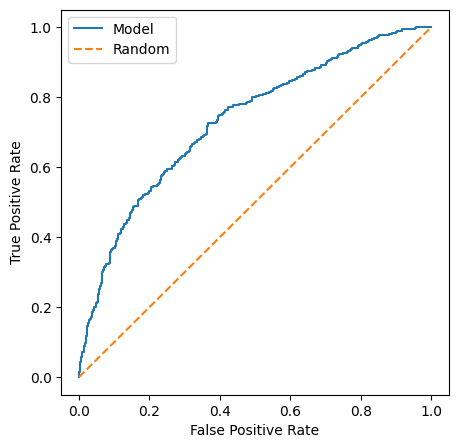

In [120]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

In [121]:
from sklearn.metrics import auc

In [122]:
auc(fpr, tpr)

np.float64(0.7318222288173319)

Задание 1

In [123]:
from sklearn.metrics import roc_auc_score

In [124]:
roc_auc_score(y_train, df_train.lead_score)

np.float64(0.7882254810906102)

In [125]:
roc_auc_score(y_train, df_train.number_of_courses_viewed)

np.float64(0.7229894623989618)

In [126]:
roc_auc_score(y_train, df_train.interaction_count)

np.float64(0.7649203047563227)

In [127]:
roc_auc_score(y_train, df_train.annual_income)

np.float64(0.6081977776250831)

Задание 2

In [128]:
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

np.float64(0.732)

Задание 3

In [129]:
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

precision = []
recall = []

for t in thresholds:
  predicted_positive = (y_pred >= t)
  predicted_negative = (y_pred < t)

  tp = (predicted_positive & actual_positive).sum()
  fp = (predicted_positive & actual_negative).sum()
  fn = (predicted_negative & actual_positive).sum()
  tn = (predicted_negative & actual_negative).sum()

  P = tp / (tp + fp)
  R = tp / (tp + fn)

  precision.append(P)
  recall.append(R)

  if round(P, 2) == round(R, 2):
    print(t)

0.63


/tmp/ipykernel_545/3695272684.py:18: RuntimeWarning: invalid value encountered in scalar divide
  P = tp / (tp + fp)


Text(0, 0.5, 'y')

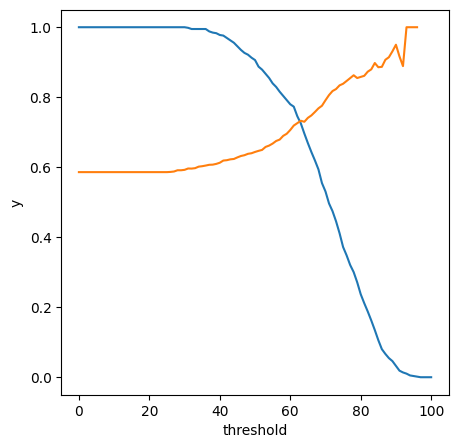

In [130]:
plt.figure(figsize=(5, 5))

plt.plot(recall)
plt.plot(precision)

plt.xlabel('threshold')
plt.ylabel('y')

Задание 4

In [131]:
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

F1_scores = []

for t in thresholds:
  predicted_positive = (y_pred >= t)
  predicted_negative = (y_pred < t)

  tp = (predicted_positive & actual_positive).sum()
  fp = (predicted_positive & actual_negative).sum()
  fn = (predicted_negative & actual_positive).sum()
  tn = (predicted_negative & actual_negative).sum()

  P = tp / (tp + fp)
  R = tp / (tp + fn)

  F1_score = 2 * (P * R) / (P + R)

  F1_scores.append((F1_score, t))

/tmp/ipykernel_545/1021762362.py:17: RuntimeWarning: invalid value encountered in scalar divide
  P = tp / (tp + fp)


In [132]:
result = max(F1_scores, key=lambda t: t[0])
result

(np.float64(0.7576158940397352), np.float64(0.41000000000000003))

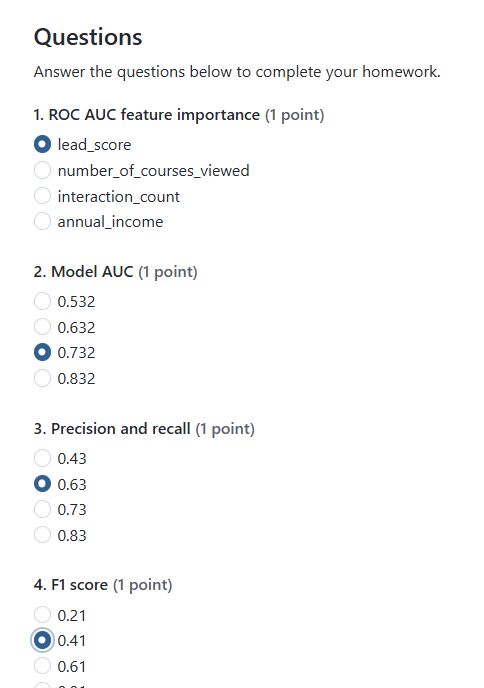

Задание 5

In [133]:
def train(df_train, y_train, C=1.0):
  dicts = df_train[feature_cols].to_dict(orient='records')

  dv = DictVectorizer(sparse=False)
  X_train = dv.fit_transform(dicts)

  model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
  model.fit(X_train, y_train)

  return dv, model

In [134]:
def predict(df, dv, model):
  dicts = df[feature_cols].to_dict(orient='records')

  X = dv.transform(dicts)
  y_pred = model.predict_proba(X)[:, 1]

  return y_pred

In [135]:
from sklearn.model_selection import KFold

In [136]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [137]:
from tqdm.auto import tqdm

In [140]:
scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
  df_train = df_full_train.iloc[train_idx]
  df_val = df_full_train.iloc[val_idx]

  y_train = df_train.converted.values
  y_val = df_val.converted.values

  dv, model = train(df_train, y_train)
  y_pred = predict(df_val, dv, model)

  auc = roc_auc_score(y_val, y_pred)
  scores.append(auc)

0it [00:00, ?it/s]

In [141]:
scores

[np.float64(0.7305601027122453),
 np.float64(0.7295726148196622),
 np.float64(0.7363428071259397),
 np.float64(0.7412454717957564),
 np.float64(0.7209138590326581)]

In [143]:
np.std(scores).round(3)

np.float64(0.007)

Задание 6

In [148]:
n_splits = 5

for C in [0.000001, 0.001, 1]:
  kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

  scores = []

  for train_idx, val_idx in kfold.split(df_full_train):
      df_train = df_full_train.iloc[train_idx]
      df_val = df_full_train.iloc[val_idx]

      y_train = df_train.converted.values
      y_val = df_val.converted.values

      dv, model = train(df_train, y_train, C=C)
      y_pred = predict(df_val, dv, model)

      auc = roc_auc_score(y_val, y_pred)
      scores.append(auc)

  print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
